###1. Data Preparation and Exploration

####Load the data

In [3]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# file path to the "Dummy Marketing and Sales " dataset
file_path = '/content/drive/MyDrive/dummy_data_hss.csv'

# Read .csv file into a Dataframe
df = pd.read_csv(file_path)

# Print first 5 rows
df.head()


,TV,Radio,Social Media,Influencer,Sales
0,16.0,6.566231,2.907983,Mega,54.732757
1,13.0,9.237765,2.409567,Mega,46.677897
2,41.0,15.886446,2.913410,Mega,150.177829
3,83.0,30.020028,6.922304,Mega,298.246340
4,15.0,8.437408,1.405998,Micro,56.594181


####Explore the data

In [5]:
# Check size of dataset (number of rows, number of columns)
df.shape

(4572, 5)

In [6]:
# Check the column names and the data types they have
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4572 entries, 0 to 4571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            4562 non-null   float64
 1   Radio         4568 non-null   float64
 2   Social Media  4566 non-null   float64
 3   Influencer    4572 non-null   object 
 4   Sales         4566 non-null   float64
dtypes: float64(4), object(1)
memory usage: 178.7+ KB


In [7]:
# Check the number of missing values in the columns
df.isnull().sum()

,0
TV,10
Radio,4
Social Media,6
Influencer,0
Sales,6


In [9]:
# Count the duplicated rows
print(f'There are {df.duplicated().sum()} duplicated rows.')

There are 0 duplicated rows.


In [10]:
# Check the summary statistics

df.describe()

,TV,Radio,Social Media,Sales
count,4562.000000,4568.000000,4566.000000,4566.000000
mean,54.066857,18.160356,3.323956,192.466602
std,26.125054,9.676958,2.212670,93.133092
min,10.000000,0.000684,0.000031,31.199409
25%,32.000000,10.525957,1.527849,112.322882
50%,53.000000,17.859513,3.055565,189.231172
75%,77.000000,25.649730,4.807558,272.507922
max,100.000000,48.871161,13.981662,364.079751


In [11]:
# Check how many categories are in the influencr column

df['Influencer'].value_counts()

,count
Influencer,
Mega,1158
Micro,1153
Nano,1139
Macro,1122


####Data cleaning

In [12]:
# There are relatively few rows with missing data compared to the number
# of rows in the entire dataset, so I shall remove the rows with missing data
df_cleaned = df.dropna()

# Check result of row removel
print(f'Rows before cleaning: {len(df)}')
print(f'Rows after cleaning: {len(df_cleaned)}')
print(f'Number of rows removed: {len(df) - len(df_cleaned)}')

Rows before cleaning: 4572
Rows after cleaning: 4546
Number of rows removed: 26


####Explore the data with data visualisations

####Histograms

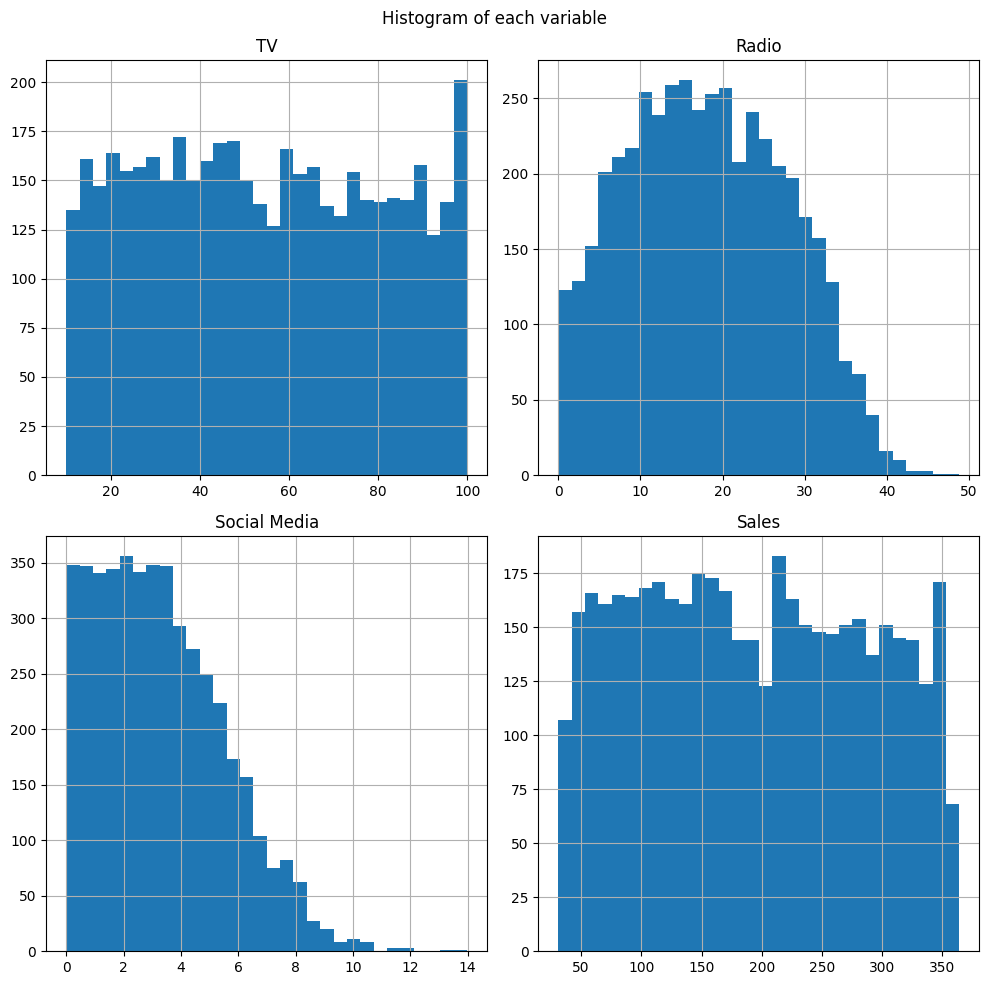

In [45]:
# Histogram for each variable
df_cleaned[['TV', 'Radio', 'Social Media', 'Sales']].hist(bins=30, figsize=(10,10))
plt.suptitle('Histogram of each variable')
plt.tight_layout()
plt.show()


Histograms show how the distribution of the values of each variable. You can tell if there are any outliers or other anomalies. These histograms shows that TV and Sales are spread evenly. Radio has more values in the middle and Social Media has many smaller values and fewer large values. There are no big outliers.

####Scatter plots

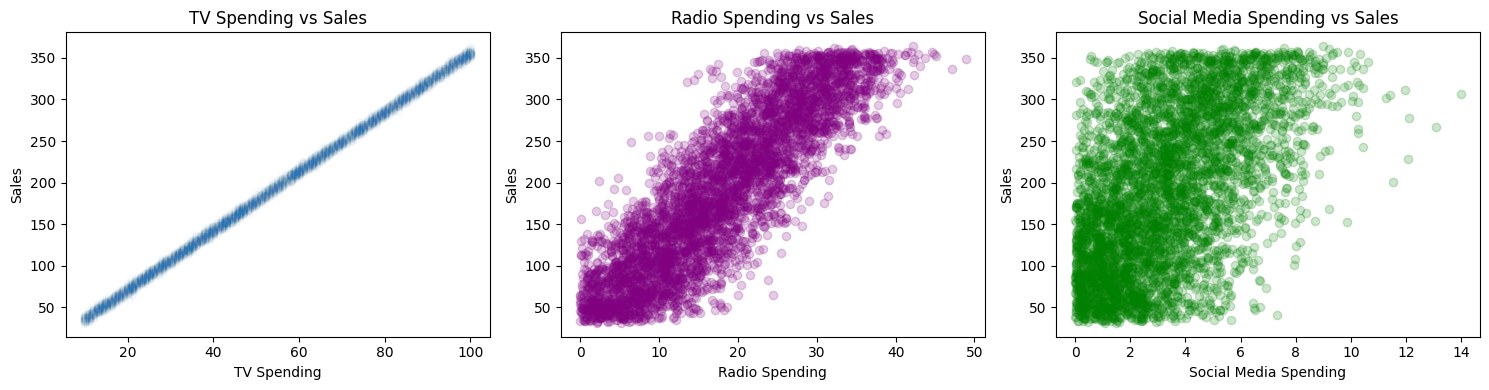

In [41]:
# Plot the figure and axes
fig = plt.figure(figsize=(15, 4))
axes = fig.subplots(1, 3)

# TV spending vs Sales
axes[0].scatter(df_cleaned['TV'], df_cleaned['Sales'], alpha=0.01)
axes[0].set_xlabel('TV Spending')
axes[0].set_ylabel('Sales')
axes[0].set_title('TV Spending vs Sales')

# Radio spending vs Sales
axes[1].scatter(df_cleaned['Radio'], df_cleaned['Sales'], alpha=0.2, color='purple')
axes[1].set_xlabel('Radio Spending')
axes[1].set_ylabel('Sales')
axes[1].set_title('Radio Spending vs Sales')

# Social Media spending vs Sales
axes[2].scatter(df_cleaned['Social Media'], df_cleaned['Sales'], alpha=0.2, color='green')
axes[2].set_xlabel('Social Media Spending')
axes[2].set_ylabel('Sales')
axes[2].set_title('Social Media Spending vs Sales')

plt.tight_layout()
plt.show()

Scatter plots show the relationship between each category of spending and Sales. This shows if there is a correlation and how strong the correlation is. If the scatter pattern is a straight line then this suggests using a linear regresison model. TV and Sales shows strong correlation, Radio vs Sales has some scatter, and Social Media has the weak relationship, even though its still somewhat linear.

####Heatmap

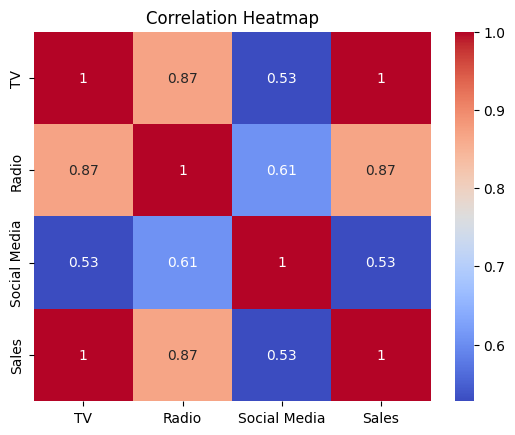

In [47]:
# Correlation between each variable and Sales
df_corr = df_cleaned[['TV', 'Radio', 'Social Media', 'Sales']].corr()
sns.heatmap(df_corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


A heatmap shows correlation between each pair of variables. The redder the pointof intersection (and higher number), the stronger the correlation.  TV has the highest correlation to Sales with 1.0. Radio is second also with a strong correlation (0.87) and Social Media (0.53 and deepest blue colour) has the weakest correlation.

###2. Regression Analysis

The scatter plots show that there is a linear relationship between each of the variables and Sales. The sales are also a continuous number. Both these factors lead to multiple linear regression as the best model.

####Preparing the data for the model

In [49]:
# First convert the Influencer categories to columns with numerical data.
# Use dummy columns with "Macro" as the baseline
df_model = pd.get_dummies(df_cleaned, columns=['Influencer'], drop_first=True, dtype=int)

# Create the independent (X) and dependent y()) variables
X = df_model.drop(columns='Sales')
y = df_model['Sales']

# Show the first 5 rows of the feature variables
X.head()

,TV,Radio,Social Media,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,16.0,6.566231,2.907983,1,0,0
1,13.0,9.237765,2.409567,1,0,0
2,41.0,15.886446,2.913410,1,0,0
3,83.0,30.020028,6.922304,1,0,0
4,15.0,8.437408,1.405998,0,1,0


In [50]:
# Split the data into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Training rows: {len(X_train)}')
print(f'Testing rows: {len(X_test)}')

Training rows: 3636
Testing rows: 910


####Training the model


In [52]:
# Create model and fitit to the training data
model = LinearRegression()
model.fit(X_train, y_train)

# show the intercept and coefficient for each feature
print(f'Intercept: {round(model.intercept_, 3)}')
coefficients = pd.DataFrame({'Feature': X.columns,
                             'Coefficient': model.coef_.round(3)})
coefficients

Intercept: -0.118


,Feature,Coefficient
0,TV,3.563
1,Radio,-0.003
2,Social Media,-0.015
3,Influencer_Mega,0.014
4,Influencer_Micro,-0.060
5,Influencer_Nano,-0.091


The intercept shows what the predicted Sales would be if every feature were 0. i.e. the value of y when x=0.
Each coefficient shows how much Sales change when that feature goes up by 1 unit, while the others stay the same. TV has a coefficient of 3.56 indicating the factor by which Sales change for every unit spent on TV. The other coefficients are almost zero meaning they have almost no effect on Sales revenue. This means that TV is the most significant and effective advertising/marekting expenditure. And also that Radio, even though it has correlation, doesn't really have an effect on Sales revenue.

In [54]:
# Predict Sales using the test data
y_pred = model.predict(X_test)

# R2 shows the variaton in Sales that the model explains
r2 = r2_score(y_test, y_pred)

# RMSE calculates the error of the prediction in same units as Sales
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R2: {round(r2, 3)}')
print(f'RMSE: {round(rmse, 2)}')
print(f'Average sales in the test: {round(y_test.mean(), 2)}')

R2: 0.999
RMSE: 2.88
Average sales in the test: 193.57


####Visualising the model's fit

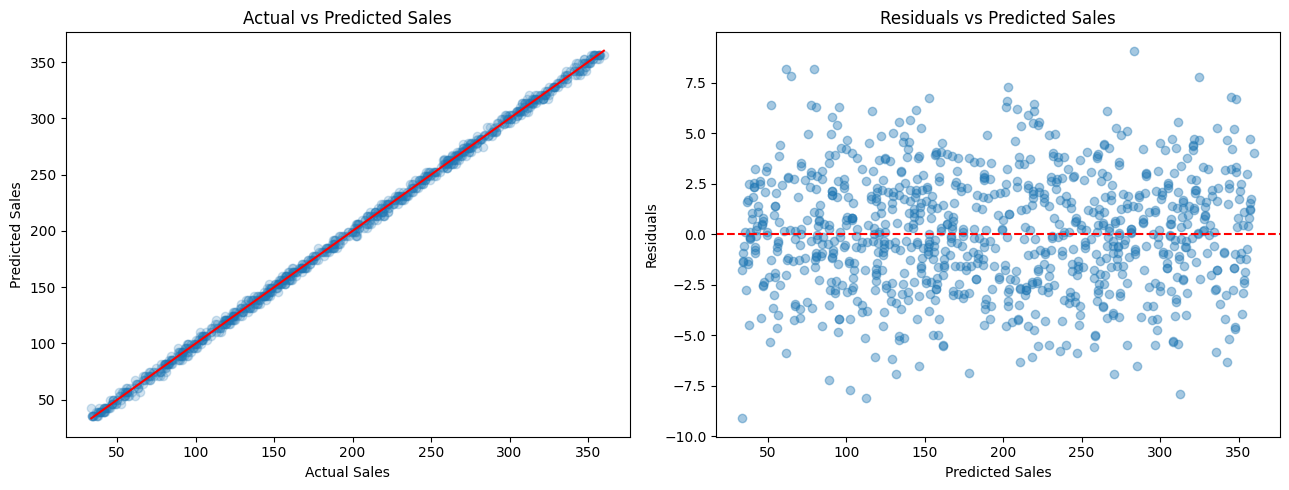

In [56]:
# Plot 1 shows the ACtual vs Predicted Sales
# Plot 2 shows residuals used to check for patterns in the errors
residuals = y_test - y_pred

fig = plt.figure(figsize=(13, 5))
axes = fig.subplots(1, 2)

# Plot 1
axes[0].scatter(y_test, y_pred, alpha=0.2)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
axes[0].set_xlabel('Actual Sales')
axes[0].set_ylabel('Predicted Sales')
axes[0].set_title('Actual vs Predicted Sales')

# Plot 2
axes[1].scatter(y_test, residuals, alpha=0.4)
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Sales')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residuals vs Predicted Sales')

plt.tight_layout()
plt.show()


In Plot 1, the predicted sales (blue dots) sit tightly on and around the actual sales (red line). This means the model makes great predictions.
In Plot 2, the errors are scattered randomly around the zero line (red dotted line) and have no curved shape. The errors are mostly between -5 and 5. this means that a straight line model fits the data well.